# Walidacja krzyżowa

**Plan notatnika:**
1. Problem: wynik zależy od losowego podziału danych
2. Idea walidacji krzyżowej
3. `cross_val_score` w praktyce
4. Ocena końcowa na zbiorze testowym
5. Jak dzielić dane: `KFold`, `StratifiedKFold`
6. Wiele metryk i wynik treningowy: `cross_validate`
7. Porównywanie modeli
8. Wyciek danych (*data leakage*) i potok
9. Dane zależne od czasu i od grup
10. Podsumowanie

## 1. Problem: wynik zależy od losowego podziału danych

Dotychczas oceniane modele sprawdzaliśmy na **jednym** zbiorze testowym. Wynik zależy jednak od tego, które obserwacje przypadkiem trafiły do zbioru testowego. Sprawdźmy to: ten sam model, te same dane, ale 100 różnych losowych podziałów.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_iris, load_diabetes
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, TimeSeriesSplit)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif

np.random.seed(42)

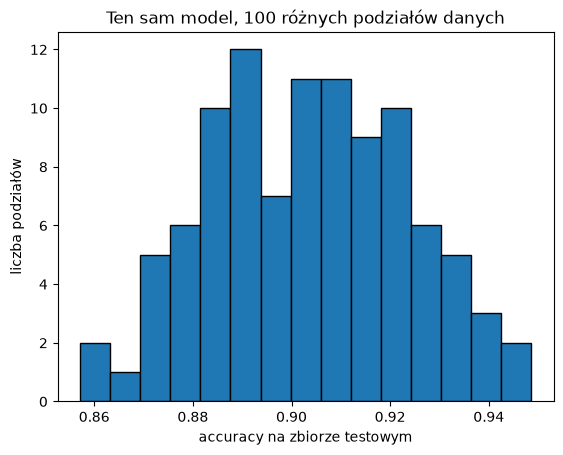

Minimum: 0.857, maksimum: 0.949, średnia: 0.903, odchylenie standardowe: 0.019


In [31]:
X, y = make_moons(n_samples=700, noise=0.25, random_state=42)

wyniki = []
for seed in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=seed)
    model = DecisionTreeClassifier(max_depth=5, min_samples_split=5, random_state=42)
    wyniki.append(model.fit(X_tr, y_tr).score(X_te, y_te))

wyniki = np.array(wyniki)

plt.hist(wyniki, bins=15, edgecolor='k')
plt.xlabel('accuracy na zbiorze testowym')
plt.ylabel('liczba podziałów')
plt.title('Ten sam model, 100 różnych podziałów danych')
plt.show()

print(f'Minimum: {wyniki.min():.3f}, maksimum: {wyniki.max():.3f}, '
      f'średnia: {wyniki.mean():.3f}, odchylenie standardowe: {wyniki.std():.3f}')

Najgorszy i najlepszy podział różnią się o ok. 9 punktów procentowych – **przy jednym podziale możemy mieć szczęście lub pecha**. Dla małych zbiorów rozrzut jest jeszcze większy. Pojedynczy zbiór testowy daje więc niepewną ocenę, a decyzje (np. który model jest lepszy, jaki dobrać hiperparametr) oparte na jednym podziale mogą być przypadkowe.

Dodatkowo, jeśli hiperparametry dobieramy, patrząc na zbiór testowy, to przestaje on być „niewidziany” – wynik jest zawyżony. Potrzebujemy więc osobnego zbioru do **wyboru modelu**. Możemy wydzielić **zbiór walidacyjny**, ale kosztem danych do nauki, a jego wynik nadal zależy od losowania. Rozwiązaniem jest walidacja krzyżowa.

## 2. Idea walidacji krzyżowej

**Walidacja krzyżowa** (*cross-validation*, CV) powtarza podział na część uczącą i walidacyjną wiele razy tak, aby **każda obserwacja choć raz posłużyła do walidacji**, a następnie uśrednia wyniki.

**Schemat K-krotnej walidacji krzyżowej** (*K-fold*):

1. Zbiór treningowy dzielimy na `K` równych części (*foldów*).
2. Model uczymy `K` razy: za każdym razem na `K-1` foldach, a ocenę liczymy na pozostałym.
3. Wyniki uśredniamy (a ich rozrzut mówi o stabilności modelu).

Przykład dla `K=5`:

| Iteracja | Uczenie (foldy) | Walidacja (fold) |
|---|---|---|
| 1 | 2, 3, 4, 5 | 1 |
| 2 | 1, 3, 4, 5 | 2 |
| 3 | 1, 2, 4, 5 | 3 |
| 4 | 1, 2, 3, 5 | 4 |
| 5 | 1, 2, 3, 4 | 5 |

![Schemat podziału na zbiór treningowy, walidacyjny i testowy](../obrazki/4.4_walidacja_schemat.png)

**Zbiór testowy zostaje poza walidacją krzyżową.** CV wykonujemy na zbiorze treningowym (do wyboru modelu i hiperparametrów), a zbiór testowy służy do jednej, końcowej oceny.

![Podział na foldy w 5-krotnej walidacji krzyżowej](../obrazki/4.4_k_fold.png)

## 3. `cross_val_score` w praktyce

Przygotujmy dane: dzielimy je na zbiór treningowy i testowy (z `stratify=y`, aby zachować proporcje klas), a walidację krzyżową wykonamy wyłącznie na zbiorze treningowym.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print(f'Zbiór treningowy: {X_train.shape}, testowy: {X_test.shape}')

Zbiór treningowy: (525, 2), testowy: (175, 2)


In [33]:
model = DecisionTreeClassifier(max_depth=5, min_samples_split=5, random_state=42)

wyniki_cv = cross_val_score(model, X_train, y_train, cv=5)

print('Wyniki w poszczególnych foldach:', wyniki_cv.round(3))
print(f'Accuracy: {wyniki_cv.mean():.3f} (+/- {wyniki_cv.std():.3f})')

Wyniki w poszczególnych foldach: [0.857 0.895 0.895 0.867 0.943]
Accuracy: 0.891 (+/- 0.030)


`cross_val_score` zwraca `accuracy` dla każdego z 5 foldów (domyślna metryka klasyfikatora). Każdy fold wymagał **osobnego uczenia modelu** na świeżej kopii – nie trzeba samodzielnie wywoływać `fit`. Średnia jest naszą oceną jakości, a odchylenie standardowe mówi, jak bardzo wynik zmienia się między foldami.

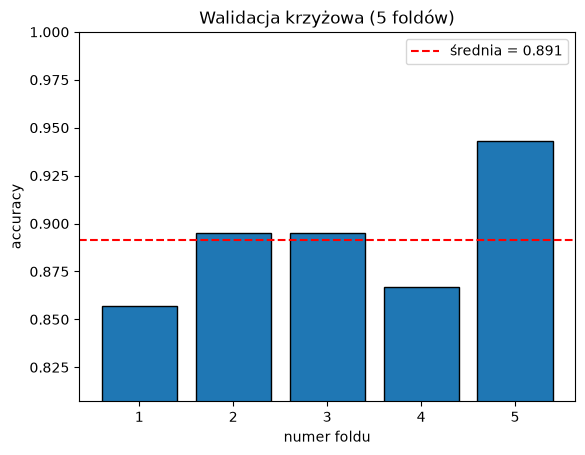

In [34]:
plt.bar(np.arange(1, 6), wyniki_cv, edgecolor='k')
plt.axhline(wyniki_cv.mean(), color='r', linestyle='--', label=f'średnia = {wyniki_cv.mean():.3f}')
plt.ylim(wyniki_cv.min() - 0.05, 1.0)
plt.xlabel('numer foldu')
plt.ylabel('accuracy')
plt.title('Walidacja krzyżowa (5 foldów)')
plt.legend()
plt.show()

### Ile foldów?

Parametr `cv` określa liczbę foldów `K`. Sprawdźmy kilka wartości:

In [35]:
wiersze = []
for k in [2, 3, 5, 10, 20]:
    s = cross_val_score(model, X_train, y_train, cv=k)
    wiersze.append({'cv (K)': k, 'średnia accuracy': s.mean(), 'odchylenie': s.std(),
                    'liczba trenowań': k})

pd.DataFrame(wiersze).set_index('cv (K)').round(3)

,średnia accuracy,odchylenie,liczba trenowań
cv (K),,,
2,0.874,0.019,2
3,0.893,0.035,3
5,0.891,0.030,5
10,0.892,0.049,10
20,0.892,0.064,20


- Przy małym `K` model uczy się na mniejszej części danych (dla `K=2` na połowie), więc wynik bywa nieco gorszy (pesymistyczny).
- Im większe `K`, tym więcej danych w uczeniu, ale **liczba trenowań rośnie** (czas obliczeń), a pojedynczy fold jest mały, więc jego wynik jest bardziej zmienny.
- W praktyce standardem jest **`K=5` lub `K=10`**.
- Odchylenie standardowe foldów opisuje zmienność wyniku, ale nie jest ścisłym przedziałem ufności, bo foldy nie są niezależne (uczą się na wspólnych danych).

## 4. Ocena końcowa na zbiorze testowym

Gdy wybraliśmy model (tu: drzewo `max_depth=5`), uczymy go na **całym zbiorze treningowym** i sprawdzamy **raz** na zbiorze testowym.

In [36]:
model.fit(X_train, y_train)
print(f'Ocena z walidacji krzyżowej (trening): {wyniki_cv.mean():.3f}')
print(f'Ocena na zbiorze testowym:             {model.score(X_test, y_test):.3f}')

Ocena z walidacji krzyżowej (trening): 0.891
Ocena na zbiorze testowym:             0.909


Obie oceny są zbliżone – walidacja krzyżowa pozwoliła **oszacować jakość modelu bez dotykania zbioru testowego**.

## 5. Jak dzielić dane: `KFold`, `StratifiedKFold`

Parametr `cv` może być liczbą lub **obiektem określającym strategię podziału**. Najważniejsze:

| Strategia | Opis |
|---|---|
| `KFold` | podział na `K` kolejnych części (opcjonalnie po losowym przemieszaniu: `shuffle=True`) |
| `StratifiedKFold` | jak `KFold`, ale w każdym foldzie **zachowane są proporcje klas** |
| `RepeatedStratifiedKFold` | powtarza walidację wielokrotnie z różnym losowaniem (stabilniejszy wynik) |
| `LeaveOneOut` | `K` = liczba obserwacji; dokładny, ale bardzo kosztowny |
| `TimeSeriesSplit`, `GroupKFold` | dane zależne od czasu lub od grup (punkt 10) |

Dla klasyfikatora podanie `cv=5` używa domyślnie **`StratifiedKFold`**, a dla regresji – `KFold` bez mieszania.

Sposób podziału ma znaczenie. Pokażmy to na zbiorze **Iris**, w którym obserwacje są ułożone **klasami po kolei** (50 × setosa, 50 × versicolor, 50 × virginica).

In [37]:
X_iris, y_iris = load_iris(return_X_y=True)
print('Klasy w kolejnych obserwacjach (co 25.):', y_iris[::25])

model_iris = LogisticRegression(max_iter=1000)

strategie = {
    'KFold (bez mieszania)': KFold(n_splits=3),
    'KFold (shuffle=True)': KFold(n_splits=3, shuffle=True, random_state=42),
    'StratifiedKFold': StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
}

for nazwa, cv in strategie.items():
    s = cross_val_score(model_iris, X_iris, y_iris, cv=cv)
    print(f'{nazwa:24s} accuracy w foldach: {s.round(3)}, średnia {s.mean():.3f}')

Klasy w kolejnych obserwacjach (co 25.): [0 0 1 1 2 2]
KFold (bez mieszania)    accuracy w foldach: [0. 0. 0.], średnia 0.000
KFold (shuffle=True)     accuracy w foldach: [1.   0.92 0.98], średnia 0.967
StratifiedKFold          accuracy w foldach: [1.   0.94 0.96], średnia 0.967


`KFold` bez mieszania na posortowanych danych daje **wynik równy 0**: w każdym foldzie walidacyjnym jest cała klasa, której model w ogóle nie widział w uczeniu. To błąd w **sposobie podziału**, a nie w modelu. Przemieszanie (`shuffle=True`) lub stratyfikacja rozwiązuje problem. Sprawdźmy proporcje klas w foldach:

In [38]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
for nr, (idx_uczenie, idx_walidacja) in enumerate(cv.split(X_iris, y_iris), start=1):
    print(f'Fold {nr}: liczebność klas w walidacji = {np.bincount(y_iris[idx_walidacja])}')

Fold 1: liczebność klas w walidacji = [17 17 16]
Fold 2: liczebność klas w walidacji = [17 16 17]
Fold 3: liczebność klas w walidacji = [16 17 17]


Stratyfikacja jest szczególnie ważna dla **danych niezbalansowanych** (rozdział 4.3), gdzie bez niej w którymś foldzie mogłoby zabraknąć klasy mniejszościowej.

## 6. Wiele metryk i wynik treningowy: `cross_validate`

`cross_val_score` zwraca jedną metrykę. Funkcja `cross_validate` pozwala policzyć **kilka metryk naraz** oraz (z `return_train_score=True`) wyniki na foldach uczących – dzięki temu widzimy przeuczenie (rozdział 4.3). Porównajmy drzewo ograniczone i nieograniczone:

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metryki = ['accuracy', 'f1', 'roc_auc']

wiersze = {}
for nazwa, m in {'drzewo max_depth=5': DecisionTreeClassifier(max_depth=5, random_state=42),
                 'drzewo bez ograniczeń': DecisionTreeClassifier(random_state=42)}.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=metryki, return_train_score=True)
    wiersze[nazwa] = {
        'accuracy (trening)': r['train_accuracy'].mean(),
        'accuracy (walidacja)': r['test_accuracy'].mean(),
        'F1 (walidacja)': r['test_f1'].mean(),
        'ROC-AUC (walidacja)': r['test_roc_auc'].mean(),
    }

pd.DataFrame(wiersze).T.round(3)

,accuracy (trening),accuracy (walidacja),F1 (walidacja),ROC-AUC (walidacja)
drzewo max_depth=5,0.933,0.874,0.873,0.929
drzewo bez ograniczeń,1.000,0.870,0.872,0.870


Drzewo bez ograniczeń ma na foldach uczących 100%, ale na walidacyjnych wyraźnie mniej – to ta sama luka między treningiem a walidacją, którą widzieliśmy w rozdziale 4.3. Zwróćmy uwagę, że w wyniku `cross_validate` metryki walidacyjne mają przedrostek `test_` (to historyczna nazwa; chodzi o foldy walidacyjne, a nie nasz zbiór testowy).

## 7. Porównywanie modeli

Walidacja krzyżowa służy też do **wyboru modelu**. Wszystkie modele oceniamy na **tych samych foldach**, aby porównanie było sprawiedliwe.

                        mean    std
kNN (k=5)              0.908  0.042
las losowy             0.903  0.039
drzewo max_depth=5     0.893  0.044
drzewo bez ograniczeń  0.884  0.042
regresja logistyczna   0.855  0.036
baseline               0.495  0.005


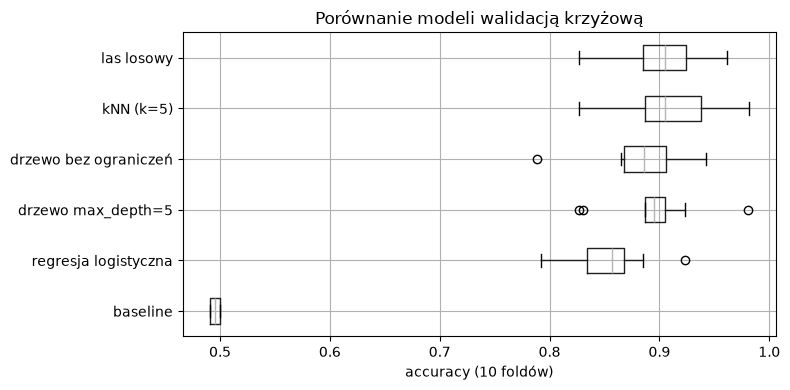

In [40]:
modele = {
    'baseline': DummyClassifier(strategy='most_frequent'),
    'regresja logistyczna': LogisticRegression(),
    'drzewo max_depth=5': DecisionTreeClassifier(max_depth=5, random_state=42),
    'drzewo bez ograniczeń': DecisionTreeClassifier(random_state=42),
    'kNN (k=5)': KNeighborsClassifier(),
    'las losowy': RandomForestClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
wyniki_modeli = {n: cross_val_score(m, X_train, y_train, cv=cv) for n, m in modele.items()}

tabela = pd.DataFrame(wyniki_modeli)
print(tabela.agg(['mean', 'std']).T.round(3).sort_values('mean', ascending=False))

tabela.boxplot(vert=False, figsize=(8, 4))
plt.xlabel('accuracy (10 foldów)')
plt.title('Porównanie modeli walidacją krzyżową')
plt.tight_layout()
plt.show()

Wykres pudełkowy pokazuje nie tylko średnią, ale też **rozrzut** wyników. Gdy pudełka dwóch modeli w dużym stopniu się pokrywają, różnica między nimi jest niewielka w porównaniu z losową zmiennością i nie ma podstaw, by uznać jeden z nich za lepszy. Tu najlepsze są kNN i las losowy, a różnica między nimi jest pomijalna. Wybrany model (lub kilka najlepszych) rozwijamy dalej, a zbiór testowy zostawiamy na ocenę końcową tylko tego jednego modelu.

## 8. Wyciek danych (*data leakage*) i potok

### Czym jest wyciek danych?

**Wyciek danych** to sytuacja, w której podczas uczenia, doboru cech lub doboru hiperparametrów model (lub my) korzysta z informacji, **których nie będzie miał w chwili rzeczywistego użycia**. Najczęściej są to informacje ze zbioru walidacyjnego lub testowego albo z przyszłości.

Skutek jest zdradliwy: **wynik walidacji jest zawyżony**, więc model wygląda świetnie, a po wdrożeniu na nowych danych wypada wyraźnie gorzej. Przeuczenie widać po różnicy między treningiem a walidacją, natomiast wyciek **jest niewidoczny w samych wynikach** – wszystko wygląda poprawnie. Dobra analogia to egzamin, na którym uczeń wcześniej widział pytania: wynik jest wysoki, ale nie mówi nic o jego wiedzy.

Najczęstsze rodzaje wycieku:

| Rodzaj | Przykład |
|---|---|
| **Przygotowanie danych przed podziałem** | skalowanie, imputacja średnią, selekcja cech, PCA, SMOTE liczone na **całym** zbiorze, a dopiero potem podział na foldy |
| **Wyciek z celu** (*target leakage*) | cecha niesie informację o wyniku, której w chwili predykcji jeszcze nie ma, np. „data wypowiedzenia umowy” przy przewidywaniu churnu lub „kwota windykacji” przy przewidywaniu niespłacenia kredytu |
| **Wyciek czasowy** | losowy podział szeregu czasowego – model uczy się na przyszłości, by przewidywać przeszłość (punkt 10) |
| **Powtórzone obserwacje i grupy** | ten sam pacjent lub zduplikowany wiersz trafia jednocześnie do uczenia i do walidacji (punkt 10) |
| **Dobór modelu po zbiorze testowym** | wielokrotne sprawdzanie zbioru testowego i poprawianie modelu, aż wynik będzie dobry (punkt 1) |

**Zasada ogólna:** walidacja ma symulować **nowe, nieznane dane**. Dlatego wszystko, co „uczy się z danych” (każde `fit`: skaler, imputer, selekcja cech, model), wykonujemy **wyłącznie na części uczącej**, a na części walidacyjnej wywołujemy już tylko `transform` / `predict`.

### Przykład 1: skalowanie przed walidacją krzyżową

Błędna kolejność: skalujemy cały zbiór treningowy, a dopiero potem dzielimy go na foldy. Średnia i odchylenie standardowe są wtedy liczone **także z obserwacji, które w danym przebiegu pełnią rolę walidacyjnych**. Poprawnie: skaler uczy się w każdym foldzie od nowa, tylko na części uczącej. Umożliwia to **potok** (`Pipeline`), który przekazujemy do `cross_val_score`.

In [41]:
# ŹLE: skalowanie całego zbioru przed walidacją krzyżową (wyciek)
X_skalowane = StandardScaler().fit_transform(X_train)
wynik_zle = cross_val_score(KNeighborsClassifier(), X_skalowane, y_train, cv=cv)

# DOBRZE: skaler w potoku jest uczony osobno w każdym foldzie
potok = make_pipeline(StandardScaler(), KNeighborsClassifier())
wynik_dobrze = cross_val_score(potok, X_train, y_train, cv=cv)

print(f'Skalowanie przed CV (wyciek): {wynik_zle.mean():.4f}')
print(f'Skalowanie w potoku:          {wynik_dobrze.mean():.4f}')

Skalowanie przed CV (wyciek): 0.9103
Skalowanie w potoku:          0.9103


Tu różnica jest znikoma, bo informacja „przecieka” tylko przez dwie liczby (średnią i odchylenie), a danych jest dużo. **Błąd w procedurze pozostaje jednak błędem**, a w innych sytuacjach skutek bywa dramatyczny, jak w kolejnym przykładzie.


## 9. Dane zależne od czasu i od grup

Losowe przemieszanie danych **nie jest odpowiednie**, gdy obserwacje są zależne od czasu (szeregi czasowe) lub należą do grup (np. kilka pomiarów od tego samego pacjenta). Model nie może wtedy uczyć się na „przyszłości”, aby przewidywać „przeszłość”, ani widzieć tego samego pacjenta jednocześnie w uczeniu i walidacji.

- **`TimeSeriesSplit`** – uczenie zawsze na wcześniejszych danych, walidacja na późniejszych:

In [44]:
for nr, (idx_uczenie, idx_walidacja) in enumerate(TimeSeriesSplit(n_splits=4).split(np.arange(10)), start=1):
    print(f'Podział {nr}: uczenie {idx_uczenie}, walidacja {idx_walidacja}')

Podział 1: uczenie [0 1], walidacja [2 3]
Podział 2: uczenie [0 1 2 3], walidacja [4 5]
Podział 3: uczenie [0 1 2 3 4 5], walidacja [6 7]
Podział 4: uczenie [0 1 2 3 4 5 6 7], walidacja [8 9]


## 10. Podsumowanie

1. Wynik na **jednym** zbiorze testowym zależy od losowego podziału; walidacja krzyżowa daje **stabilniejszą ocenę** i wykorzystuje wszystkie dane treningowe.
2. Standardowo stosujemy `K=5` lub `K=10`, a dla klasyfikacji – **`StratifiedKFold`**.
3. CV wykonujemy **na zbiorze treningowym**; zbiór testowy zostawiamy na jedną, końcową ocenę.
4. `cross_validate` pozwala policzyć kilka metryk oraz wyniki treningowe (diagnoza przeuczenia).
5. Modele porównujemy na **tych samych foldach**, patrząc na średnią i rozrzut.
6. **Wyciek danych** (informacje z walidacji w uczeniu) zawyża wynik; wszystko, co uczy się z danych, umieszczamy w **potoku**.